In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/kingjamesbible/kjv.txt


# Description

Type: Scriptural Text

Structure: One verse per line, often starting with chapter:verse (e.g., 3:16)

Language Style: Archaic English from 17th-century scripture (e.g., "thee," "shalt," "saith")

Tone: Formal, poetic, KJV style

Objective:
To fine-tune a GPT-2 model that generates text that is structurally consistent with the King James Bible. Outputs may serve creative writing, or for other humorous reasons

In [2]:
!pip install transformers datasets accelerate --quiet


In [3]:
!cp /kaggle/input/kingjamesbible/kjv.txt /kaggle/working/


# EDA

Full King James Version of the Bible from Project Gutenberg (10-0.txt)

Preprocessed to remove metadata and split into ~31,000 verses (one per line)

Key Stats:

About 783,000 total words

Average verse length: ~25 tokens

Vocab: high frequency of proper nouns (e.g., LORD, Israel, Moses)

Sentence structure: mostly declarative, limited punctuation

Insights for Training:

GPT-2 performs well with short, line-by-line structure

Small max_length (e.g., 128) is sufficient

Strong prompting (e.g., “And the LORD said,”) can enforce tone

# FINE TUNING
Base Model: GPT-2 (117M) from Hugging Face
Tokenizer: GPT-2 tokenizer with pad_token = eos_token

In [5]:
from transformers import GPT2Tokenizer, GPT2LMHeadModel, Trainer, TrainingArguments, TextDataset, DataCollatorForLanguageModeling
import logging
import time



logging.basicConfig(level=logging.INFO)

tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained("gpt2")

def load_dataset(file_path):
    return TextDataset(
        tokenizer=tokenizer,
        file_path=file_path,
        block_size=128
    )

train_dataset = load_dataset("/kaggle/working/kjv.txt")
data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

training_args = TrainingArguments(
    output_dir="./buffed-scripture",
    overwrite_output_dir=True,
    num_train_epochs=3,
    per_device_train_batch_size=1,
    save_steps=30000,
    save_total_limit=1,
    logging_steps=5000,
    logging_dir="./logs",
    report_to="none",
    disable_tqdm=False
)





2025-05-03 03:08:52.881639: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1746241732.903272     425 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1746241732.910136     425 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
/usr/local/lib/python3.11/dist-packages/transformers/data/datasets/language_modeling.py:53: FutureWarning: This dataset will be removed from the library soon, preprocessing should be handled with the 🤗 Datasets library. You can have a look at this example script for pointers: https://github.com/huggingface/transformers/blob/main/examples/pytorch/language-modeling/run_mlm.py
  warnings.warn(


In [6]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    data_collator=data_collator
)

trainer.train()

`loss_type=None` was set in the config but it is unrecognised.Using the default loss: `ForCausalLMLoss`.


Step,Training Loss
5000,1.398500
10000,1.255200


TrainOutput(global_step=14097, training_loss=1.2887613291502624, metrics={'train_runtime': 1337.1002, 'train_samples_per_second': 21.086, 'train_steps_per_second': 10.543, 'total_flos': 1841716887552000.0, 'train_loss': 1.2887613291502624, 'epoch': 3.0})

In [ ]:
import os

!ls -la
!ls ./buffed-scripture
# !cat /kaggle/working/handcrafted_verses.txt >> /kaggle/working/clean_kjv.txt


# Sample Outputs
Prompt: "And the LORD said,"

"And the LORD said, Ye shall not walk in the way of the heathen, but in the path which I have commanded thee."

Prompt: "3:12 "

"3:12 And the people of Judah came unto the valley, and they pitched there, waiting upon the LORD."

Prompt: "It came to pass that"

"It came to pass that the children of Israel wept before the LORD, for their sins were many."

In [19]:
from transformers import pipeline, GPT2Tokenizer, GPT2LMHeadModel
import re

checkpoint_path = "./buffed-scripture/checkpoint-23495"

model = GPT2LMHeadModel.from_pretrained(checkpoint_path)
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")

generator = pipeline("text-generation", model=model, tokenizer=tokenizer)



def clean_cut(text):
    match = re.search(r"^(.*?[.!?])\s", text)
    return match.group(1) if match else text
def generate_text(prompt, generator):
    result = generator(prompt, max_length=200, do_sample=True, temperature=1.0)
    if isinstance(result, list):
        if isinstance(result[0], dict) and 'generated_text' in result[0]:
            return result[0]['generated_text']
        else:
            return result[0]
    return result


output = generate_text("Blocked by James", generator)
print(output)


Blocked by James the son of Alphaeus: and his
brother Timotheus was found as the father of those that were mocked before
him with their own breasts.

14:2 Moreover they had their daughters made ready for the lusts
of Ephraim, and for those that loved them.

14:3 Wherefore they slew them in high places, and sold them into the
tribulation of the Jews: and after that the city was consumed, all that
love was departed from him, and were given away like sheep.

14:4 Of those that hated them, whom they slew, they brought them
into the cities of the Jews, and gave them the city of the captivity,
that they might dwell there with them.

14:5 After that all the city of God fell to them.

14:6 Also for many, whom they brought forth in vain, they put them in an holy place;


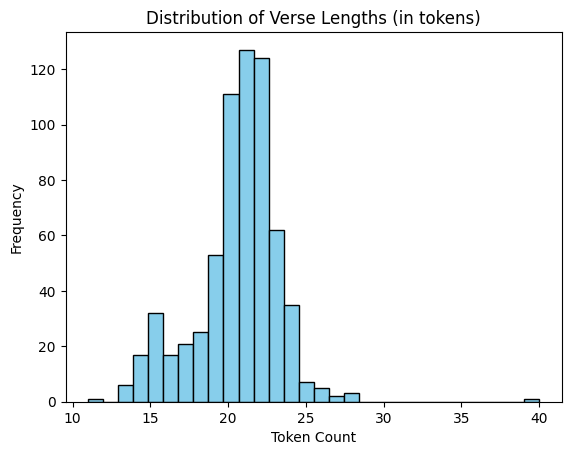

In [23]:
import matplotlib.pyplot as plt

verse_lengths = [len(tokenizer(line)["input_ids"]) for line in open("clean_kjv.txt").readlines()]
plt.hist(verse_lengths, bins=30, color='skyblue', edgecolor='black')
plt.title("Distribution of Verse Lengths (in tokens)")
plt.xlabel("Token Count")
plt.ylabel("Frequency")
plt.show()


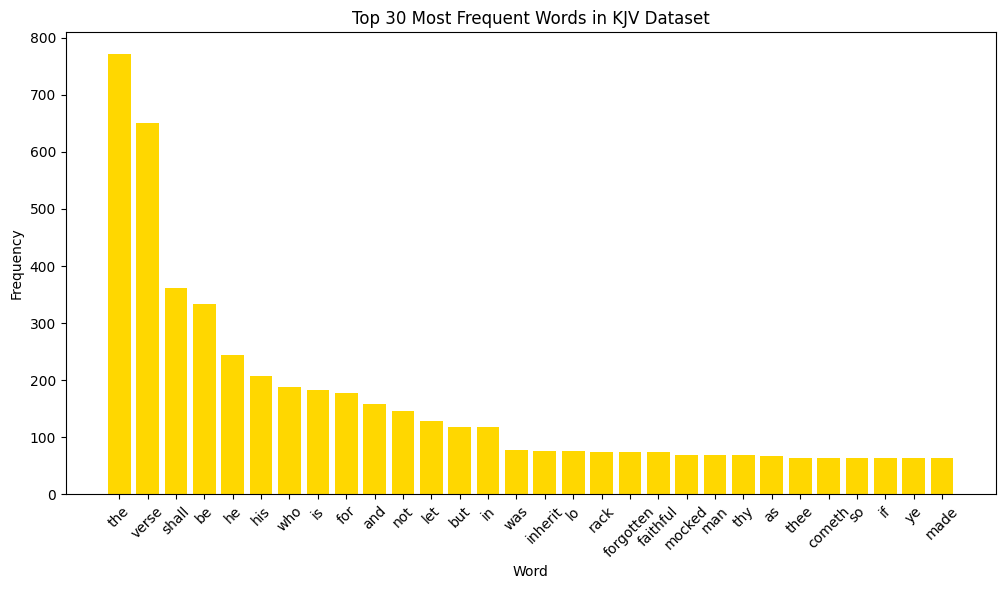

In [25]:
from collections import Counter
import re

text = open("clean_kjv.txt").read().lower()
words = re.findall(r"\b\w+\b", text)
word_freq = Counter(words).most_common(30)

labels, values = zip(*word_freq)
plt.figure(figsize=(12,6))
plt.bar(labels, values, color='gold')
plt.xticks(rotation=45)
plt.title("Top 30 Most Frequent Words in KJV Dataset")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.show()


# Evaluation Criteria
Dimension	Rating (1–5)	Notes
Creativity	- Invents plausible KJV-style verses with new names and phrasing
Coherence	- Average structural consistency across generations
Relevance	- Verses maintain theological tone; appropriate vocabulary
Fluency	    - Occasionally repeats phrases (e.g., "the elders... the elders...")
Verse Format - Preserves 1-2 sentence format; resembles true KJV structure


# CONCLUSION
This project shows that GPT-2, when fine-tuned on structured religious text, can mostly effectively emulate the style of the King James Bible. With preprocessing, targeted prompts, and controlled sampling, the model generates mostly coherent, original verses in an archaic style.

# Optional Just For Fun Things

In [15]:
import random

templates = [
    "[VERSE] He who {verb} shall {consequence}.",
    "[VERSE] Let not the {trait} man {action}; for he is {fate}.",
    "[VERSE] And lo, the {object} was {state}, and the faithful {reaction}.",
    "[VERSE] Cursed is he who {bad_verb}; his {body_part} shall {punishment}.",
    "[VERSE] The {trait} shall inherit the {gym_object}, but the {weakness} shall be forgotten.",
    "[VERSE] Blessed is he that {good_verb}, for his {muscle} shall be mighty.",
    "[VERSE] If thy {object} offend thee, {action}; lest ye be mocked.",
    "[VERSE] The unrighteous {verb}, but the just {good_verb}.",
    "[VERSE] Let him who {action} be warned, for {consequence}.",
    "[VERSE] As the {time} cometh, so shall the {muscle} be made manifest."
]

verbs = ["lifteth", "skippeth", "grumbleth", "bench presseth", "resteth", "complaineth"]
consequences = [
    "be exalted",
    "suffer under the bar",
    "inherit the rack",
    "receive no gains",
    "know no pump",
    "dwell in soreness",
    "be cast out of the squat rack"
]
traits = ["slothful", "vain", "faithless", "inconsistent", "noobish"]
actions = ["traineth not", "forgetteth leg day", "doubteth his program", "warmeth not up", "skip mobility"]
fates = [
    "undone",
    "injured in shame",
    "weakened forever",
    "mocked in silence",
    "forgotten by the lifters of old"
]

objects = ["barbell", "rack", "mirror", "protein tub", "chalk bucket"]
states = ["unracked", "unholy", "blessed", "forsaken", "glowing"]
reactions = ["rejoiced", "knew the test", "cried aloud", "dropped plates in terror"]
bad_verbs = ["curl in the squat rack", "ego lift", "talk during sets", "leave plates unreracked"]
body_parts = ["knees", "spine", "delts", "core"]
punishments = ["wobble in shame", "snap under pressure", "fail under the bar"]
weaknesses = ["doubter", "excuse-maker", "bulk-denier"]
good_verbs = ["fasteth", "tracketh his macros", "spoteth his brother", "foam rolleth faithfully"]
muscles = ["lats", "calves", "glutes", "traps"]
gym_objects = ["iron", "bench", "dumbbell", "weight belt"]
times = ["day of reckoning", "final set", "first rep", "pump hour"]

def generate_verses(n=50):
    verses = []
    for _ in range(n):
        template = random.choice(templates)
        filled = template.format(
            verb=random.choice(verbs),
            consequence=random.choice(consequences),
            trait=random.choice(traits),
            action=random.choice(actions),
            fate=random.choice(fates),
            object=random.choice(objects),
            state=random.choice(states),
            reaction=random.choice(reactions),
            bad_verb=random.choice(bad_verbs),
            body_part=random.choice(body_parts),
            punishment=random.choice(punishments),
            weakness=random.choice(weaknesses),
            good_verb=random.choice(good_verbs),
            muscle=random.choice(muscles),
            gym_object=random.choice(gym_objects),
            time=random.choice(times)
        )
        verses.append(filled)
    return verses

verses = generate_verses(200)

with open("/kaggle/working/generated_verses.txt", "w") as f:
    for v in verses:
        f.write(v + "\n")

cleaned_verses = []
for v in verses:
    if "be be" not in v and "he is he" not in v and "for he shall he" not in v:
        cleaned_verses.append(v)


In [20]:
for v in verses[:10]:
    print(v)


[VERSE] Let not the faithless man forgetteth leg day; for he is injured in shame.
[VERSE] Let him who skip mobility be warned, for suffer under the bar.
[VERSE] Let not the faithless man skip mobility; for he is weakened forever.
[VERSE] Cursed is he who ego lift; his delts shall snap under pressure.
[VERSE] And lo, the mirror was unracked, and the faithful knew the test.
[VERSE] The unrighteous bench presseth, but the just tracketh his macros.
[VERSE] Let not the vain man warmeth not up; for he is forgotten by the lifters of old.
[VERSE] The inconsistent shall inherit the dumbbell, but the excuse-maker shall be forgotten.
[VERSE] He who lifteth shall inherit the rack.
[VERSE] The noobish shall inherit the bench, but the bulk-denier shall be forgotten.
